# Checkpoint 5 — 2º Semestre | Tecnólogo em Inteligência Artificial
**Disciplinas:** Machine Learning & Modelling e Statistical Computing with R & Python
**Dataset:** Wines — Kaggle (harrywang/wine-dataset-for-clustering)

| Integrante | RM |
|---|---|
| Adalberto Alves Cruz | 574115 |
| Bruno Henrique Ferreira Ambrosio | 571218 |
| Gustavo da Silva Nascimento | 570821 |
| Lucas Maximo dos Santos | 569714 |
| Renan de Assis Rodrigues | 574049 |
| Tiago Thomaz Cesaro | 569374 |

## 0. Configuração e carga dos dados

In [1]:
import os
import io
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# Semente fixa para o K-means gerar sempre o mesmo resultado
SEED = 42
np.random.seed(SEED)

In [2]:
# Carga com três tentativas, para o notebook rodar em qualquer máquina do grupo:
#   1) arquivo do Kaggle na pasta do notebook
#   2) download da versão do GitHub (gist), padronizando os nomes das colunas
#   3) upload manual (somente no Colab)

ARQUIVO_LOCAL = "wine-clustering.csv"
URL_GIST = "https://gist.githubusercontent.com/tijptjik/9408623/raw/wine.csv"

COLUNAS = ["Alcohol", "Malic_Acid", "Ash", "Ash_Alcanity", "Magnesium",
           "Total_Phenols", "Flavanoids", "Nonflavanoid_Phenols",
           "Proanthocyanins", "Color_Intensity", "Hue", "OD280", "Proline"]

# O gist usa outros nomes e traz a coluna "Wine" (classe)
MAPA_GIST = {"Malic.acid": "Malic_Acid", "Acl": "Ash_Alcanity", "Mg": "Magnesium",
             "Phenols": "Total_Phenols", "Nonflavanoid.phenols": "Nonflavanoid_Phenols",
             "Proanth": "Proanthocyanins", "Color.int": "Color_Intensity",
             "OD": "OD280"}


def ler_csv_seguro(origem):
    """Lê o CSV e devolve None se estiver vazio ou corrompido."""
    try:
        df = pd.read_csv(origem)
        if df.empty:
            print(f"Aviso: {origem} está vazio.")
            return None
        return df
    except (pd.errors.ParserError, pd.errors.EmptyDataError, UnicodeDecodeError) as e:
        print(f"Aviso: {origem} corrompido ou ilegível ({e}).")
        return None


def carregar_dataset():
    if os.path.exists(ARQUIVO_LOCAL):
        df = ler_csv_seguro(ARQUIVO_LOCAL)
        if df is not None:
            print(f"Carregado do arquivo local: {ARQUIVO_LOCAL}")
            return df

    try:
        df = pd.read_csv(URL_GIST).rename(columns=MAPA_GIST)
        df = df.drop(columns=["Wine"], errors="ignore")
        print("Carregado do GitHub (gist), coluna de classe removida.")
        return df
    except Exception as e:
        print(f"Não foi possível baixar do GitHub ({type(e).__name__}).")

    try:
        from google.colab import files
        print("Selecione o arquivo wine-clustering.csv:")
        enviado = files.upload()
        if enviado:
            nome = next(iter(enviado))
            df = ler_csv_seguro(io.BytesIO(enviado[nome]))
            if df is not None:
                print(f"Carregado via upload: {nome}")
                return df
    except ImportError:
        pass

    raise FileNotFoundError(
        "Dataset não encontrado. Coloque o 'wine-clustering.csv' na pasta "
        "do notebook e rode a célula novamente.")


df = carregar_dataset()

Carregado do arquivo local: wine-clustering.csv


In [3]:
# Validação: colunas esperadas, tipos numéricos, nulos e duplicatas
faltando = [c for c in COLUNAS if c not in df.columns]
if faltando:
    raise ValueError(f"Colunas ausentes no dataset: {faltando}")

df = df[COLUNAS].apply(pd.to_numeric, errors="coerce")

print("Nulos por coluna:", int(df.isna().sum().sum()))
print("Linhas duplicadas:", int(df.duplicated().sum()))
print("Dimensão:", df.shape)
df.head()

Nulos por coluna: 0
Linhas duplicadas: 0
Dimensão: (178, 13)


,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline
0,14.2300,1.7100,2.4300,15.6000,127,2.8000,3.0600,0.2800,2.2900,5.6400,1.0400,3.9200,1065
1,13.2000,1.7800,2.1400,11.2000,100,2.6500,2.7600,0.2600,1.2800,4.3800,1.0500,3.4000,1050
2,13.1600,2.3600,2.6700,18.6000,101,2.8000,3.2400,0.3000,2.8100,5.6800,1.0300,3.1700,1185
3,14.3700,1.9500,2.5000,16.8000,113,3.8500,3.4900,0.2400,2.1800,7.8000,0.8600,3.4500,1480
4,13.2400,2.5900,2.8700,21.0000,118,2.8000,2.6900,0.3900,1.8200,4.3200,1.0400,2.9300,735


# PARTE 1 — Statistical Computing with R & Python

Variáveis escolhidas:
- **Alcohol** — teor alcoólico (%)
- **Malic_Acid** — ácido málico (g/L), indicador de acidez

As duas se conectam às perguntas da Parte 2 (qual grupo tem mais álcool e qual é mais ácido)
e têm comportamentos diferentes: uma é quase simétrica e a outra é assimétrica.

## a) Visualização dos dados: tabela de distribuição de frequências e gráfico

In [4]:
def tabela_frequencia(serie):
    """Tabela de frequências com classes definidas pela regra de Sturges."""
    n = len(serie)
    k = int(np.ceil(1 + 3.322 * np.log10(n)))          # número de classes
    amplitude = (serie.max() - serie.min()) / k           # amplitude de cada classe
    limites = [serie.min() + i * amplitude for i in range(k + 1)]
    limites[-1] = serie.max() + 1e-9                     # inclui o valor máximo

    classes = pd.cut(serie, bins=limites, right=False)
    fi = classes.value_counts().sort_index()

    tabela = pd.DataFrame({
        "Classe": [f"{i.left:.2f} |- {i.right:.2f}" for i in fi.index],
        "xi (ponto médio)": [(i.left + i.right) / 2 for i in fi.index],
        "fi": fi.values,
        "fri (%)": fi.values / n * 100,
        "Fi": fi.cumsum().values,
        "Fri (%)": fi.cumsum().values / n * 100,
    })
    return tabela, k, amplitude


tab_alc, k_alc, h_alc = tabela_frequencia(df["Alcohol"])
print(f"Alcohol: {k_alc} classes (Sturges), amplitude de classe = {h_alc:.3f}")
tab_alc

Alcohol: 9 classes (Sturges), amplitude de classe = 0.422


,Classe,xi (ponto médio),fi,fri (%),Fi,Fri (%)
0,11.03 |- 11.45,11.2410,3,1.6854,3,1.6854
1,11.45 |- 11.87,11.6630,15,8.4270,18,10.1124
2,11.87 |- 12.30,12.0855,23,12.9213,41,23.0337
3,12.30 |- 12.72,12.5080,28,15.7303,69,38.7640
4,12.72 |- 13.14,12.9300,28,15.7303,97,54.4944
5,13.14 |- 13.56,13.3520,30,16.8539,127,71.3483
6,13.56 |- 13.99,13.7745,29,16.2921,156,87.6404
7,13.99 |- 14.41,14.1970,20,11.2360,176,98.8764
8,14.41 |- 14.83,14.6190,2,1.1236,178,100.0000


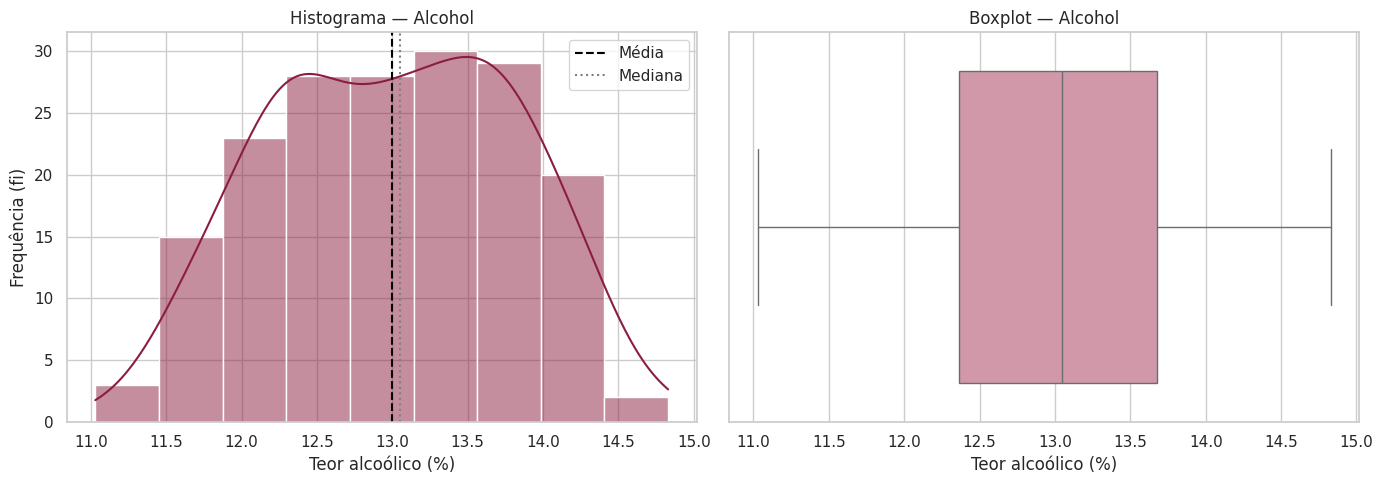

In [5]:
# Interpretação (Alcohol):
# - As quatro classes centrais (12,30 a 13,99%) concentram 64% dos vinhos;
#   as classes das pontas têm apenas 3 e 2 vinhos. Forma aproximada de sino.
# - Pela frequência acumulada, 54% dos vinhos ficam abaixo de 13,14%,
#   coerente com média (13,00%) e mediana (13,05%) praticamente iguais.
# - Não há uma classe com pico isolado muito alto: os dados se espalham de forma
#   relativamente uniforme no centro (característica de distribuição platicúrtica).

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["Alcohol"], bins=k_alc, kde=True, color="#8B1E3F", ax=ax[0])
ax[0].axvline(df["Alcohol"].mean(), color="black", ls="--", label="Média")
ax[0].axvline(df["Alcohol"].median(), color="gray", ls=":", label="Mediana")
ax[0].set_title("Histograma — Alcohol")
ax[0].set_xlabel("Teor alcoólico (%)")
ax[0].set_ylabel("Frequência (fi)")
ax[0].legend()

sns.boxplot(x=df["Alcohol"], color="#D98FA6", ax=ax[1])
ax[1].set_title("Boxplot — Alcohol")
ax[1].set_xlabel("Teor alcoólico (%)")

plt.tight_layout()
plt.show()

# Leitura dos gráficos:
# - O histograma mostra formato simétrico, com média e mediana sobrepostas.
# - O boxplot não aponta outliers: todos os vinhos ficam entre 11,03% e 14,83%.

In [6]:
tab_mal, k_mal, h_mal = tabela_frequencia(df["Malic_Acid"])
print(f"Malic_Acid: {k_mal} classes (Sturges), amplitude de classe = {h_mal:.3f}")
tab_mal

Malic_Acid: 9 classes (Sturges), amplitude de classe = 0.562


,Classe,xi (ponto médio),fi,fri (%),Fi,Fri (%)
0,0.74 |- 1.30,1.0210,21,11.7978,21,11.7978
1,1.30 |- 1.86,1.5830,68,38.2022,89,50.0000
2,1.86 |- 2.43,2.1455,25,14.0449,114,64.0449
3,2.43 |- 2.99,2.7080,16,8.9888,130,73.0337
4,2.99 |- 3.55,3.2700,16,8.9888,146,82.0225
5,3.55 |- 4.11,3.8320,17,9.5506,163,91.5730
6,4.11 |- 4.68,4.3945,8,4.4944,171,96.0674
7,4.68 |- 5.24,4.9570,4,2.2472,175,98.3146
8,5.24 |- 5.80,5.5190,3,1.6854,178,100.0000


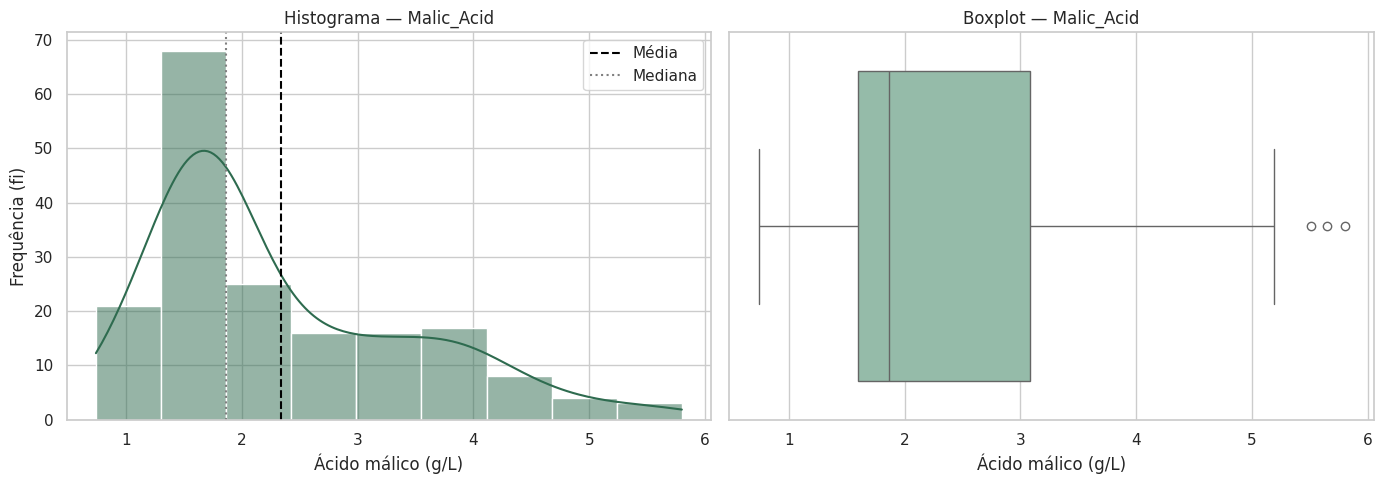

In [7]:
# Interpretação (Malic_Acid):
# - Só a classe de 1,30 a 1,86 g/L concentra 38% dos vinhos, e até 2,43 g/L já estão 64%.
# - A partir daí a frequência cai e aparece uma "cauda" longa até 5,8 g/L,
#   com apenas 3 vinhos na última classe.
# - Ou seja: a maioria dos vinhos tem pouca acidez málica e um grupo menor
#   tem acidez bem elevada. É uma distribuição assimétrica à direita.

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["Malic_Acid"], bins=k_mal, kde=True, color="#2E6B4F", ax=ax[0])
ax[0].axvline(df["Malic_Acid"].mean(), color="black", ls="--", label="Média")
ax[0].axvline(df["Malic_Acid"].median(), color="gray", ls=":", label="Mediana")
ax[0].set_title("Histograma — Malic_Acid")
ax[0].set_xlabel("Ácido málico (g/L)")
ax[0].set_ylabel("Frequência (fi)")
ax[0].legend()

sns.boxplot(x=df["Malic_Acid"], color="#8FC1A9", ax=ax[1])
ax[1].set_title("Boxplot — Malic_Acid")
ax[1].set_xlabel("Ácido málico (g/L)")

plt.tight_layout()
plt.show()

# Leitura dos gráficos:
# - A média fica à direita da mediana, puxada pelos vinhos muito ácidos.
# - O boxplot mostra a caixa comprimida à esquerda e bigode longo à direita,
#   com alguns pontos acima do limite superior (possíveis outliers).

## b) Análise descritiva: tendência central, dispersão e separatrizes

In [8]:
def descritiva(serie):
    q1, q2, q3 = serie.quantile([0.25, 0.50, 0.75])
    iqr = q3 - q1
    return pd.Series({
        # Tendência central
        "Média": serie.mean(),
        "Mediana": serie.median(),
        "Moda": ", ".join(f"{m:.2f}" for m in serie.mode()),
        # Dispersão
        "Mínimo": serie.min(),
        "Máximo": serie.max(),
        "Amplitude total": serie.max() - serie.min(),
        "Variância": serie.var(),
        "Desvio padrão": serie.std(),
        "Coef. de variação (%)": serie.std() / serie.mean() * 100,
        # Separatrizes
        "Q1 (25%)": q1,
        "Q2 (50%)": q2,
        "Q3 (75%)": q3,
        "Amplitude interquartil": iqr,
        "Limite inferior (outlier)": q1 - 1.5 * iqr,
        "Limite superior (outlier)": q3 + 1.5 * iqr,
        # Forma
        "Assimetria": stats.skew(serie),
        "Curtose": stats.kurtosis(serie),
    })


resumo = pd.DataFrame({"Alcohol": descritiva(df["Alcohol"]),
                       "Malic_Acid": descritiva(df["Malic_Acid"])})
resumo

,Alcohol,Malic_Acid
Média,13.0006,2.3363
Mediana,13.0500,1.8650
Moda,"12.37, 13.05",1.73
Mínimo,11.0300,0.7400
Máximo,14.8300,5.8000
Amplitude total,3.8000,5.0600
Variância,0.6591,1.2480
Desvio padrão,0.8118,1.1171
Coef. de variação (%),6.2445,47.8159
Q1 (25%),12.3625,1.6025


In [9]:
# Outliers pelo critério do boxplot (1,5 x IQR)
for var in ["Alcohol", "Malic_Acid"]:
    q1, q3 = df[var].quantile([0.25, 0.75])
    iqr = q3 - q1
    fora = df[(df[var] < q1 - 1.5 * iqr) | (df[var] > q3 + 1.5 * iqr)][var]
    print(f"{var}: {len(fora)} outlier(s) -> {sorted(fora.round(2).tolist())}")

Alcohol: 0 outlier(s) -> []
Malic_Acid: 3 outlier(s) -> [5.51, 5.65, 5.8]


In [10]:
# INTERPRETAÇÃO — ALCOHOL
# Tendência central:
#   Média 13,00%, mediana 13,05% e modas 12,37% e 13,05% (bimodal).
#   Média e mediana quase iguais confirmam a simetria vista no histograma,
#   então a média representa bem o teor alcoólico típico.
# Dispersão:
#   Desvio padrão de 0,81 ponto percentual e coeficiente de variação de 6,2%.
#   CV abaixo de 15% indica baixa dispersão: os vinhos têm teor alcoólico
#   bem parecido entre si (de 11,03% a 14,83%).
# Separatrizes:
#   Q1 = 12,36%, Q2 = 13,05%, Q3 = 13,68%.
#   25% dos vinhos têm menos de 12,36% de álcool e 25% têm mais de 13,68%.
#   Os 50% centrais ficam numa faixa estreita de 1,3 ponto percentual.
#   Nenhum outlier.
# Forma:
#   Assimetria -0,05 (praticamente simétrica) e curtose -0,86 (platicúrtica,
#   ou seja, mais "achatada" que a Normal, com dados espalhados no centro).

# INTERPRETAÇÃO — MALIC_ACID
# Tendência central:
#   Média 2,34 g/L, bem acima da mediana 1,87 g/L; moda 1,73 g/L.
#   A ordem Moda < Mediana < Média é típica de assimetria à direita.
#   Aqui a mediana é a medida mais representativa, pois a média é inflada
#   pelos vinhos muito ácidos.
# Dispersão:
#   Desvio padrão de 1,12 g/L e coeficiente de variação de 47,8%.
#   CV acima de 30% indica alta dispersão: a acidez varia muito entre os vinhos
#   (de 0,74 a 5,80 g/L, quase 8 vezes de diferença).
# Separatrizes:
#   Q1 = 1,60, Q2 = 1,87, Q3 = 3,08 g/L.
#   A distância Q1 -> Q2 (0,26) é muito menor que Q2 -> Q3 (1,22): metade dos vinhos
#   está comprimida em valores baixos e a outra metade se espalha para cima.
#   Há 3 outliers acima de 5,30 g/L.
# Forma:
#   Assimetria +1,03 (assimetria positiva moderada/forte).

# COMPARAÇÃO
#   O teor alcoólico é uma característica estável entre os vinhos,
#   enquanto a acidez é o que mais diferencia um vinho do outro entre as duas.
#   Isso sugere que a acidez pode ajudar a separar grupos na Parte 2.

## c) Análise probabilística: distribuição de probabilidade e cálculos

In [11]:
# Distribuição escolhida para Alcohol: NORMAL
# Justificativa: assimetria próxima de zero e média ~ mediana.
# Parâmetros estimados a partir da amostra:
mu = df["Alcohol"].mean()
sigma = df["Alcohol"].std()
print(f"Alcohol ~ Normal(mu = {mu:.4f}, sigma = {sigma:.4f})")

# Teste de Shapiro-Wilk (H0: os dados seguem distribuição Normal)
for var in ["Alcohol", "Malic_Acid"]:
    w, p = stats.shapiro(df[var])
    print(f"Shapiro-Wilk {var}: W = {w:.4f}, p-valor = {p:.4g}")

# Interpretação:
# - Alcohol: p = 0,02. Pelo teste formal, a normalidade é rejeitada a 5%,
#   por causa da curtose negativa (distribuição mais achatada). Mesmo assim,
#   a simetria e o W alto (0,98) mostram que a Normal é uma boa aproximação,
#   o que vamos confirmar comparando probabilidades teóricas com as observadas.
# - Malic_Acid: p praticamente zero e W = 0,89. A Normal NÃO é adequada,
#   o que já era esperado pela assimetria forte.

Alcohol ~ Normal(mu = 13.0006, sigma = 0.8118)
Shapiro-Wilk Alcohol: W = 0.9818, p-valor = 0.02005
Shapiro-Wilk Malic_Acid: W = 0.8888, p-valor = 2.946e-10


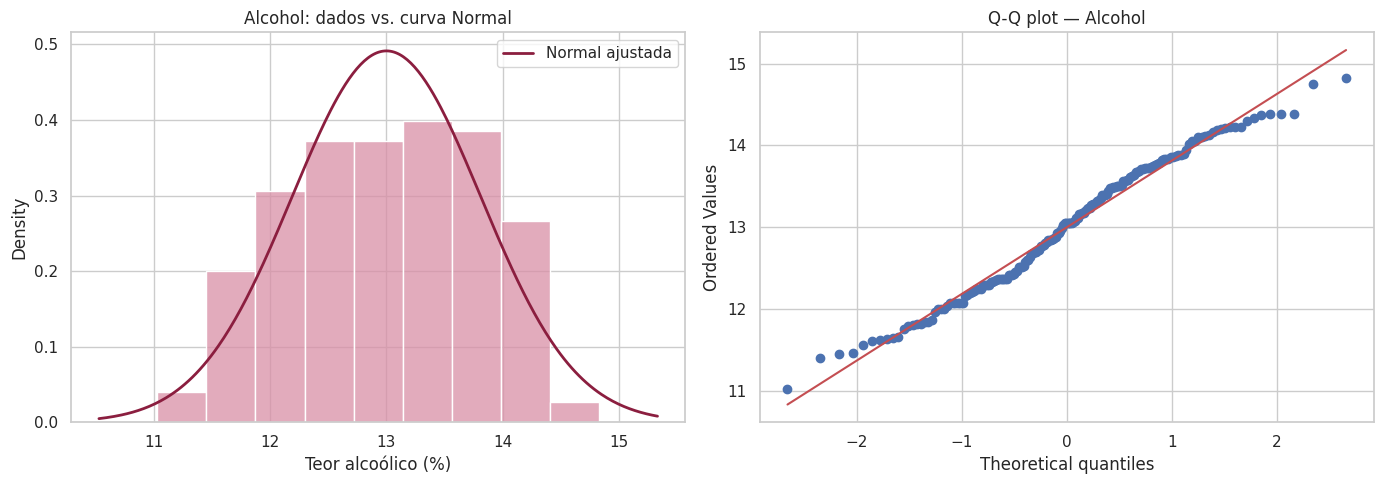

In [12]:
x = np.linspace(df["Alcohol"].min() - 0.5, df["Alcohol"].max() + 0.5, 300)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["Alcohol"], bins=k_alc, stat="density", color="#D98FA6", ax=ax[0])
ax[0].plot(x, stats.norm.pdf(x, mu, sigma), color="#8B1E3F", lw=2, label="Normal ajustada")
ax[0].set_title("Alcohol: dados vs. curva Normal")
ax[0].set_xlabel("Teor alcoólico (%)")
ax[0].legend()

stats.probplot(df["Alcohol"], dist="norm", plot=ax[1])
ax[1].set_title("Q-Q plot — Alcohol")

plt.tight_layout()
plt.show()

# Leitura: a curva acompanha bem o histograma e os pontos do Q-Q plot seguem
# a reta na maior parte, desviando só um pouco nas pontas (efeito da curtose negativa).

In [13]:
# CÁLCULO 1 — P(Alcohol > 14%): vinhos com teor alcoólico alto
p1_teo = 1 - stats.norm.cdf(14, mu, sigma)
p1_emp = (df["Alcohol"] > 14).mean()
print(f"P(X > 14)       teórica = {p1_teo:.2%} | observada = {p1_emp:.2%}")

# CÁLCULO 2 — P(12% < Alcohol < 13%): faixa intermediária
p2_teo = stats.norm.cdf(13, mu, sigma) - stats.norm.cdf(12, mu, sigma)
p2_emp = ((df["Alcohol"] > 12) & (df["Alcohol"] < 13)).mean()
print(f"P(12 < X < 13)  teórica = {p2_teo:.2%} | observada = {p2_emp:.2%}")

# CÁLCULO 3 — P(Alcohol < 12%): vinhos mais leves
p3_teo = stats.norm.cdf(12, mu, sigma)
p3_emp = (df["Alcohol"] < 12).mean()
print(f"P(X < 12)       teórica = {p3_teo:.2%} | observada = {p3_emp:.2%}")

# CÁLCULO 4 — Teor alcoólico que separa os 10% mais fortes (percentil 90)
p90 = stats.norm.ppf(0.90, mu, sigma)
print(f"Percentil 90    teórico = {p90:.2f}% | observado = {df['Alcohol'].quantile(0.90):.2f}%")

# Interpretação:
# - Cerca de 11% dos vinhos devem ter mais de 14% de álcool (observado: 12,4%).
# - Cerca de 39% ficam entre 12% e 13% (observado: 36%).
# - Cerca de 11% têm menos de 12% (observado: 10,7%).
# - Um vinho precisa ter mais de ~14,04% de álcool para estar entre os 10% mais fortes.
# As diferenças entre teórico e observado ficam em poucos pontos percentuais,
# confirmando que a Normal é uma aproximação útil para o teor alcoólico.

P(X > 14)       teórica = 10.92% | observada = 12.36%
P(12 < X < 13)  teórica = 39.08% | observada = 35.96%
P(X < 12)       teórica = 10.89% | observada = 10.67%
Percentil 90    teórico = 14.04% | observado = 14.10%


In [14]:
# Malic_Acid: como a Normal não serve, usamos a distribuição EMPÍRICA
# (proporções observadas) e comparamos com o que a Normal erraria.
m_mal, s_mal = df["Malic_Acid"].mean(), df["Malic_Acid"].std()

# CÁLCULO 5 — P(Malic_Acid > 3 g/L): vinhos de acidez alta
p5_emp = (df["Malic_Acid"] > 3).mean()
p5_norm = 1 - stats.norm.cdf(3, m_mal, s_mal)
print(f"P(Y > 3)   observada = {p5_emp:.2%} | Normal = {p5_norm:.2%}")

# CÁLCULO 6 — P(Malic_Acid < 1 g/L): vinhos de acidez muito baixa
p6_emp = (df["Malic_Acid"] < 1).mean()
p6_norm = stats.norm.cdf(1, m_mal, s_mal)
print(f"P(Y < 1)   observada = {p6_emp:.2%} | Normal = {p6_norm:.2%}")

# Probabilidade de valor negativo pela Normal (impossível na prática)
print(f"P(Y < 0)   pela Normal = {stats.norm.cdf(0, m_mal, s_mal):.2%}")

# Interpretação:
# - Cerca de 1 em cada 4 vinhos (26%) tem acidez acima de 3 g/L.
# - Na cauda direita a Normal até chega perto (27,6% contra 26,4%), mas erra feio
#   na esquerda: prevê 11,6% de vinhos abaixo de 1 g/L quando só 4,5% existem,
#   e ainda atribui 1,8% de chance de acidez negativa, o que é impossível.
# - Conclusão: para variáveis assimétricas, a distribuição empírica
#   (ou uma distribuição assimétrica) é mais adequada que a Normal.

P(Y > 3)   observada = 26.40% | Normal = 27.62%
P(Y < 1)   observada = 4.49% | Normal = 11.58%
P(Y < 0)   pela Normal = 1.82%


# PARTE 2 — Machine Learning & Modelling

## a) Introdução

**Problema:** o dataset traz 178 vinhos descritos por 13 medidas químicas, sem nenhum rótulo
dizendo a que tipo cada vinho pertence. Comparar vinhos olhando 13 variáveis ao mesmo tempo
é inviável manualmente.

**Solução proposta:** aplicar o algoritmo **K-means**, uma técnica de aprendizado
não supervisionado, para agrupar automaticamente os vinhos mais parecidos entre si.
O número de grupos é escolhido pelos métodos **Elbow** e **Silhouette Score**, e cada grupo
é descrito pelas suas características médias (teor alcoólico, acidez, cor, fenóis etc.).
O resultado permite, por exemplo, que uma vinícola ou distribuidora segmente seu catálogo
por perfil químico.

## b) Pré-processamento dos dados

In [15]:
# 1) Features sem relevância / de classe
#    A versão do Kaggle não tem coluna de classe. Se o dataset vier do GitHub,
#    a coluna "Wine" já foi removida na carga. Conferimos aqui mesmo assim:
colunas_classe = [c for c in df.columns if c.lower() in ("wine", "class", "classe", "type")]
X_df = df.drop(columns=colunas_classe)
print("Colunas de classe removidas:", colunas_classe if colunas_classe else "nenhuma")
print("Features usadas:", X_df.shape[1])

# 2) Dados nulos: preenchemos com a mediana (robusta a outliers) caso existam
nulos = X_df.isna().sum().sum()
if nulos > 0:
    X_df = X_df.fillna(X_df.median())
print("Nulos tratados:", int(nulos))

# 3) Duplicatas
dup = X_df.duplicated().sum()
if dup > 0:
    X_df = X_df.drop_duplicates()
print("Duplicatas removidas:", int(dup))

Colunas de classe removidas: nenhuma
Features usadas: 13
Nulos tratados: 0
Duplicatas removidas: 0


In [16]:
# 4) Por que padronizar?
#    As variáveis têm escalas muito diferentes. O K-means usa distância euclidiana,
#    então Proline (centenas) dominaria completamente Hue (em torno de 1).
X_df.describe().T[["mean", "std", "min", "max"]]

,mean,std,min,max
Alcohol,13.0006,0.8118,11.0300,14.8300
Malic_Acid,2.3363,1.1171,0.7400,5.8000
Ash,2.3665,0.2743,1.3600,3.2300
Ash_Alcanity,19.4949,3.3396,10.6000,30.0000
Magnesium,99.7416,14.2825,70.0000,162.0000
Total_Phenols,2.2951,0.6259,0.9800,3.8800
Flavanoids,2.0293,0.9989,0.3400,5.0800
Nonflavanoid_Phenols,0.3619,0.1245,0.1300,0.6600
Proanthocyanins,1.5909,0.5724,0.4100,3.5800
Color_Intensity,5.0581,2.3183,1.2800,13.0000


In [17]:
# Padronização (z-score): cada variável passa a ter média 0 e desvio padrão 1,
# e todas contribuem de forma equilibrada para a distância.
scaler = StandardScaler()
X = scaler.fit_transform(X_df)

pd.DataFrame(X, columns=X_df.columns).describe().T[["mean", "std"]].round(2)

,mean,std
Alcohol,-0.0000,1.0000
Malic_Acid,-0.0000,1.0000
Ash,-0.0000,1.0000
Ash_Alcanity,-0.0000,1.0000
Magnesium,-0.0000,1.0000
Total_Phenols,0.0000,1.0000
Flavanoids,-0.0000,1.0000
Nonflavanoid_Phenols,0.0000,1.0000
Proanthocyanins,-0.0000,1.0000
Color_Intensity,0.0000,1.0000


## d) Número ideal de grupos: Elbow e Silhouette Score

In [18]:
# Testamos k de 2 a 10.
# Elbow: inércia (soma das distâncias ao quadrado de cada ponto ao seu centróide).
#        Buscamos o "cotovelo", ponto a partir do qual aumentar k melhora pouco.
# Silhouette: mede o quanto cada ponto está próximo do seu grupo e longe dos outros
#        (varia de -1 a 1; quanto maior, melhor a separação).
ks = range(2, 11)
inercias, silhuetas = [], []

for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED)
    rotulos = km.fit_predict(X)
    inercias.append(km.inertia_)
    silhuetas.append(silhouette_score(X, rotulos))

resultado_k = pd.DataFrame({"k": list(ks), "Inércia": inercias, "Silhouette": silhuetas})
resultado_k

,k,Inércia,Silhouette
0,2,"1,658.7589",0.2593
1,3,"1,277.9285",0.2849
2,4,"1,175.4283",0.2602
3,5,"1,109.5127",0.2016
4,6,"1,046.0023",0.2372
5,7,981.5952,0.2036
6,8,935.2012,0.1570
7,9,889.8929,0.1499
8,10,845.8952,0.1436


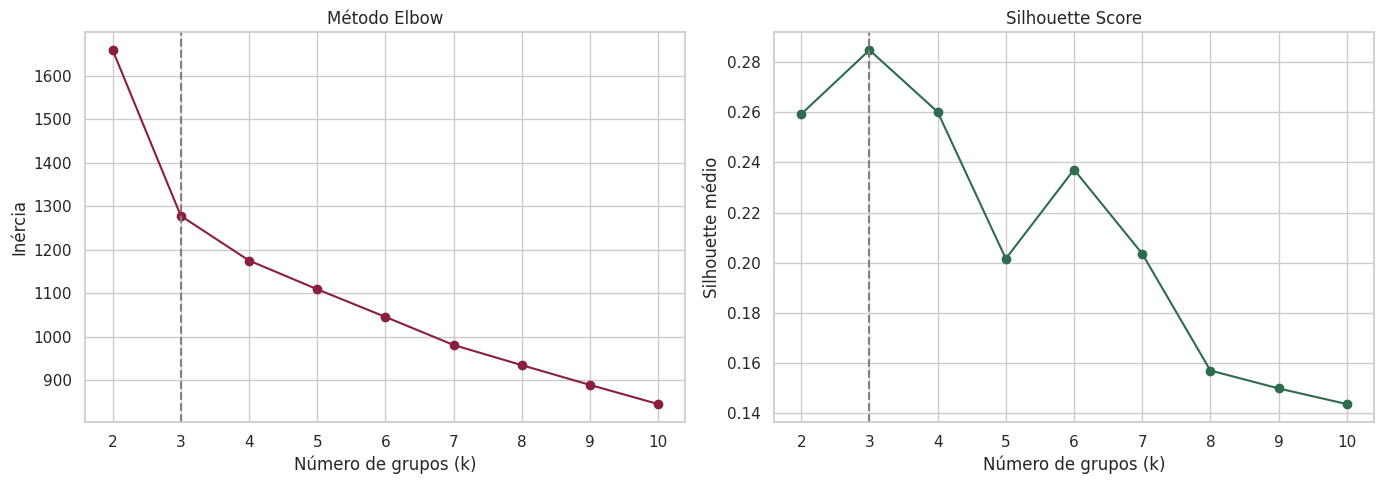

k com maior Silhouette: 3


In [19]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(list(ks), inercias, marker="o", color="#8B1E3F")
ax[0].axvline(3, color="gray", ls="--")
ax[0].set_title("Método Elbow")
ax[0].set_xlabel("Número de grupos (k)")
ax[0].set_ylabel("Inércia")

ax[1].plot(list(ks), silhuetas, marker="o", color="#2E6B4F")
ax[1].axvline(3, color="gray", ls="--")
ax[1].set_title("Silhouette Score")
ax[1].set_xlabel("Número de grupos (k)")
ax[1].set_ylabel("Silhouette médio")

plt.tight_layout()
plt.show()

k_ideal = int(resultado_k.loc[resultado_k["Silhouette"].idxmax(), "k"])
print("k com maior Silhouette:", k_ideal)

# Interpretação:
# - Elbow: a inércia cai forte de k=2 para k=3 (1659 -> 1278) e, depois disso,
#   as quedas ficam bem menores. O cotovelo está em k = 3.
# - Silhouette: o maior valor é em k = 3 (0,285). A partir de k=5 o índice cai,
#   indicando grupos cada vez menos separados.
# - Os dois métodos concordam: 3 grupos.

## c) Ajuste do K-means

In [20]:
# Ajuste final com k = 3.
# n_init=10: o algoritmo roda 10 vezes com centróides iniciais diferentes
#            e fica com a melhor solução (menor inércia).
kmeans = KMeans(n_clusters=k_ideal, n_init=10, random_state=SEED)
rotulos = kmeans.fit_predict(X)

# Renumeramos os grupos em ordem crescente de teor alcoólico
# (Grupo 1 = menos alcoólico), para a numeração ser estável e fácil de interpretar.
ordem = X_df.assign(c=rotulos).groupby("c")["Alcohol"].mean().sort_values().index
mapa = {antigo: novo for novo, antigo in enumerate(ordem, start=1)}

df_grupos = X_df.copy()
df_grupos["Grupo"] = pd.Series(rotulos, index=X_df.index).map(mapa)

print(f"Inércia final: {kmeans.inertia_:.2f}")
print(f"Silhouette final: {silhouette_score(X, rotulos):.4f}")
print("\nVinhos por grupo:")
print(df_grupos["Grupo"].value_counts().sort_index())

Inércia final: 1277.93
Silhouette final: 0.2849

Vinhos por grupo:
Grupo
1    65
2    51
3    62
Name: count, dtype: int64


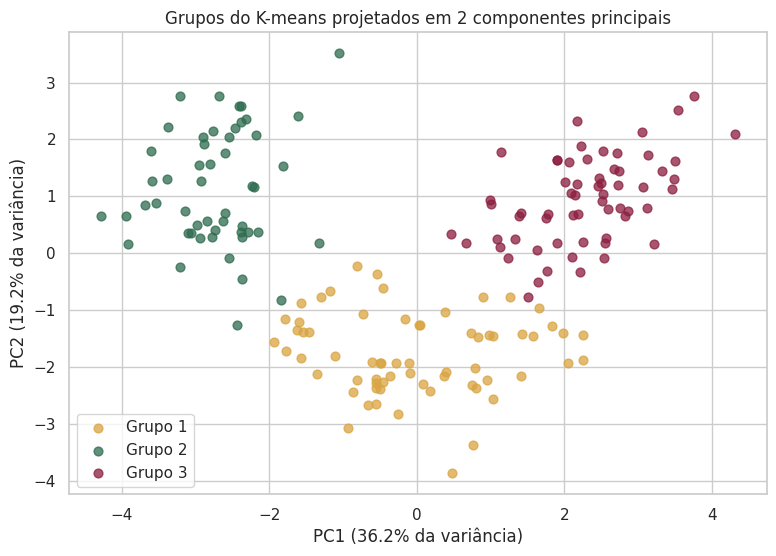

In [21]:
# Visualização dos grupos em 2D com PCA
# O PCA reduz as 13 variáveis para 2 componentes, apenas para desenhar o gráfico.
pca = PCA(n_components=2, random_state=SEED)
comp = pca.fit_transform(X)
var_exp = pca.explained_variance_ratio_

cores = {1: "#D9A441", 2: "#2E6B4F", 3: "#8B1E3F"}
plt.figure(figsize=(9, 6))
for g, cor in cores.items():
    m = df_grupos["Grupo"].values == g
    plt.scatter(comp[m, 0], comp[m, 1], s=40, alpha=0.75, color=cor, label=f"Grupo {g}")

plt.xlabel(f"PC1 ({var_exp[0]:.1%} da variância)")
plt.ylabel(f"PC2 ({var_exp[1]:.1%} da variância)")
plt.title("Grupos do K-means projetados em 2 componentes principais")
plt.legend()
plt.show()

# Interpretação: os três grupos aparecem como regiões bem distintas no plano,
# com pouca sobreposição, o que confirma visualmente a escolha de k = 3.

## e) Análise dos grupos e características dos vinhos

In [22]:
# Perfil médio de cada grupo (valores na escala original)
perfil = df_grupos.groupby("Grupo").mean().T
perfil["Média geral"] = X_df.mean()
perfil

Grupo,1,2,3,Média geral
Alcohol,12.2509,13.1341,13.6768,13.0006
Malic_Acid,1.8974,3.3073,1.9979,2.3363
Ash,2.2312,2.4176,2.4663,2.3665
Ash_Alcanity,20.0631,21.2412,17.4629,19.4949
Magnesium,92.7385,98.6667,107.9677,99.7416
Total_Phenols,2.2477,1.6839,2.8476,2.2951
Flavanoids,2.0500,0.8188,3.0032,2.0293
Nonflavanoid_Phenols,0.3577,0.4520,0.2921,0.3619
Proanthocyanins,1.6242,1.1459,1.9221,1.5909
Color_Intensity,2.9731,7.2347,5.4535,5.0581


In [23]:
# Perguntas do enunciado
alc = df_grupos.groupby("Grupo")["Alcohol"].agg(["mean", "min", "max"])
print("Teor alcoólico por grupo (%):")
print(alc.round(2))

acido = df_grupos.groupby("Grupo")["Malic_Acid"].mean()
print(f"\nGrupo mais ácido: Grupo {acido.idxmax()} ({acido.max():.2f} g/L de ácido málico)")
print(f"Grupo menos ácido: Grupo {acido.idxmin()} ({acido.min():.2f} g/L)")

Teor alcoólico por grupo (%):
         mean     min     max
Grupo                        
1     12.2500 11.0300 13.8600
2     13.1300 12.2000 14.3400
3     13.6800 11.5600 14.8300

Grupo mais ácido: Grupo 2 (3.31 g/L de ácido málico)
Grupo menos ácido: Grupo 1 (1.90 g/L)


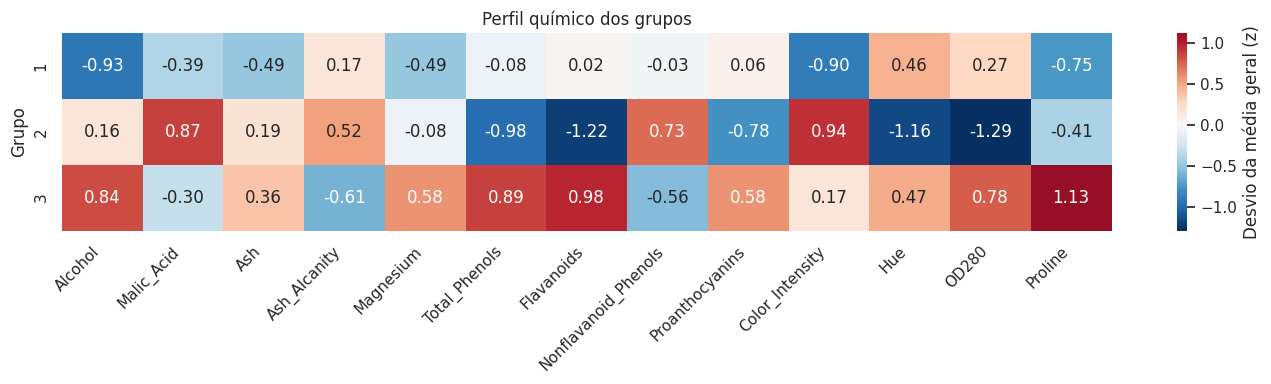

In [24]:
# Mapa de calor com os perfis padronizados (z-score médio por grupo):
# vermelho = acima da média geral, azul = abaixo.
perfil_z = pd.DataFrame(X, columns=X_df.columns).assign(Grupo=df_grupos["Grupo"].values)
perfil_z = perfil_z.groupby("Grupo").mean()

plt.figure(figsize=(14, 4))
sns.heatmap(perfil_z, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            cbar_kws={"label": "Desvio da média geral (z)"})
plt.title("Perfil químico dos grupos")
plt.ylabel("Grupo")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

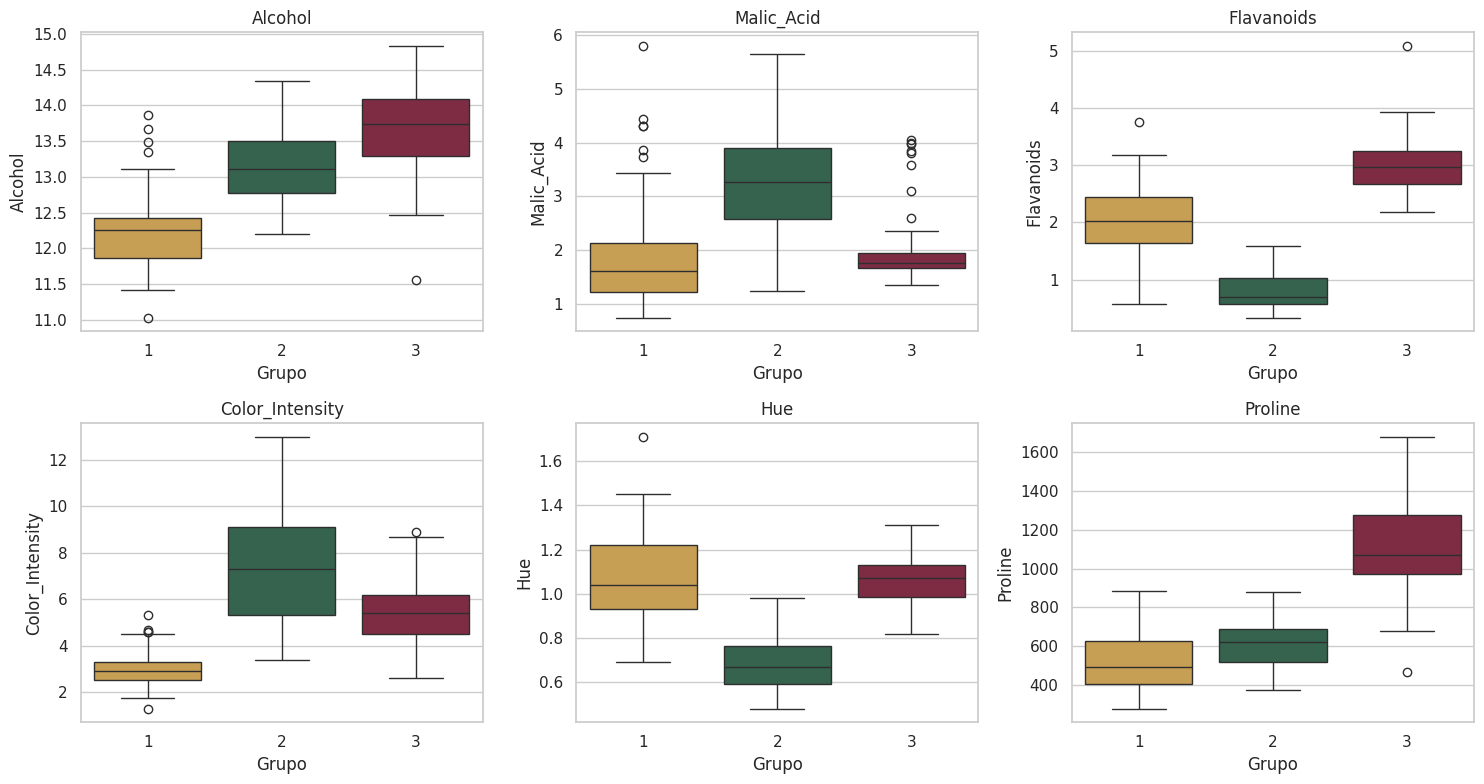

In [25]:
# Comparação visual das variáveis principais por grupo
vars_chave = ["Alcohol", "Malic_Acid", "Flavanoids", "Color_Intensity", "Hue", "Proline"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, var in zip(axes.flat, vars_chave):
    sns.boxplot(data=df_grupos, x="Grupo", y=var, hue="Grupo", palette=list(cores.values()), legend=False, ax=ax)
    ax.set_title(var)
plt.tight_layout()
plt.show()

### Conclusão: perfil de cada grupo

**Grupo 1 — Vinhos leves e suaves (65 vinhos)**
- Menor teor alcoólico: média de 12,25%.
- Acidez baixa (1,90 g/L), a menor entre os grupos.
- Cor mais clara (intensidade 2,97) e menor teor de prolina (510).
- Pouca cinza (2,23) e pouco magnésio.
- Perfil: vinhos mais leves, menos encorpados.

**Grupo 2 — Vinhos ácidos e de cor intensa (51 vinhos)**
- Teor alcoólico intermediário: média de 13,13%.
- **Grupo mais ácido**: 3,31 g/L de ácido málico, cerca de 70% acima dos outros grupos.
- Cor mais intensa (7,23) e menor tonalidade (hue 0,69).
- Menos flavonoides (0,82) e fenóis totais (1,68), e mais fenóis não flavonoides.
- Perfil: vinhos ácidos, escuros e com menos compostos fenólicos.

**Grupo 3 — Vinhos fortes e encorpados (62 vinhos)**
- **Maior teor alcoólico**: média de 13,68%.
- Acidez baixa (2,00 g/L), próxima do Grupo 1.
- Maior teor de prolina (1100, o dobro dos outros), flavonoides (3,00) e fenóis totais (2,85).
- Mais magnésio e mais cinza, com menor alcalinidade da cinza.
- Perfil: vinhos mais alcoólicos e ricos em compostos fenólicos, típicos de vinhos encorpados.

**Síntese:** o teor alcoólico separa bem o Grupo 1 dos demais; a acidez é o que distingue o
Grupo 2; e a prolina e os flavonoides caracterizam o Grupo 3. Esses resultados conversam com a
Parte 1: o álcool varia pouco no geral (CV 6,2%) mas é suficiente para diferenciar grupos, e a
alta dispersão do ácido málico (CV 47,8%) se explica por um grupo específico de vinhos muito ácidos.